In [85]:
import numpy as np
import pandas as pd

In [61]:
df=pd.read_csv("D:\\work\\data\\raw\\data.csv")
df.shape

(1512, 15)

In [62]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1512 entries, 0 to 1511
Data columns (total 15 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Shipment_ID                         1512 non-null   str    
 1   Dispatch_Date                       1512 non-null   str    
 2   Product_Type                        1475 non-null   str    
 3   Storage_Condition                   1475 non-null   str    
 4   Initial_Shelf_Life_Hours            1475 non-null   float64
 5   Avg_Temperature_C                   1475 non-null   float64
 6   Min_Temperature_C                   1475 non-null   float64
 7   Max_Temperature_C                   1475 non-null   float64
 8   Temperature_Fluctuation_C           1475 non-null   float64
 9   Relative_Humidity_pct               1476 non-null   float64
 10  Transit_Elapsed_Hours               1475 non-null   float64
 11  Expected_Transit_Remaining_Hours    1475 non-null   fl

In [63]:
df.isnull().sum()

Shipment_ID                            0
Dispatch_Date                          0
Product_Type                          37
Storage_Condition                     37
Initial_Shelf_Life_Hours              37
Avg_Temperature_C                     37
Min_Temperature_C                     37
Max_Temperature_C                     37
Temperature_Fluctuation_C             37
Relative_Humidity_pct                 36
Transit_Elapsed_Hours                 37
Expected_Transit_Remaining_Hours      37
Hours_Above_Product_Temp_Threshold    37
Unplanned_Delay_Hours                 37
Remaining_Shelf_Life_Hours            37
dtype: int64

In [64]:
print(df.duplicated().sum())

7


In [65]:
# Examine categorical values
print("Product types:")
print(df["Product_Type"].value_counts(dropna=False))

print("\nStorage conditions:")
print(df["Storage_Condition"].value_counts(dropna=False)) #added dropna=False so that it does not remove null values while considering the value counts

# Understand the target variable
print("\nRemaining shelf life information:")
print(df["Remaining_Shelf_Life_Hours"].describe())

# Check duplicate shipment IDs
print("\nDuplicate shipment IDs:", df["Shipment_ID"].duplicated().sum())

Product types:
Product_Type
Strawberries     277
Leafy Greens     260
Tomatoes         249
Bell Peppers     235
Blueberries      228
Bananas          222
NaN               37
Leafy Greens       3
Blueberries        1
Name: count, dtype: int64

Storage conditions:
Storage_Condition
Refrigerated    1026
Insulated        314
Ambient          131
NaN               37
refrigerated       4
Name: count, dtype: int64

Remaining shelf life information:
count    1475.000000
mean      115.894915
std        56.300753
min         0.000000
25%        74.100000
50%       109.100000
75%       156.900000
max       259.400000
Name: Remaining_Shelf_Life_Hours, dtype: float64

Duplicate shipment IDs: 12


In [66]:
# shipment IDs that occur more than once
duplicate_ids = df[df["Shipment_ID"].duplicated(keep=False)].sort_values("Shipment_ID")
display(duplicate_ids.head())
# display(duplicate_ids)

,Shipment_ID,Dispatch_Date,Product_Type,Storage_Condition,Initial_Shelf_Life_Hours,Avg_Temperature_C,Min_Temperature_C,Max_Temperature_C,Temperature_Fluctuation_C,Relative_Humidity_pct,Transit_Elapsed_Hours,Expected_Transit_Remaining_Hours,Hours_Above_Product_Temp_Threshold,Unplanned_Delay_Hours,Remaining_Shelf_Life_Hours
226,SHP-00227,2025-04-23,Blueberries,Refrigerated,163.1,2.34,-0.60,5.17,5.78,96.6,22.1,30.4,2.3,4.5,136.7
1510,SHP-00227,2025-04-23,Blueberries,Refrigerated,163.1,2.34,-0.60,5.17,5.78,96.6,22.1,30.4,2.3,4.5,136.7
296,SHP-00297,2025-01-11,Blueberries,Refrigerated,126.7,5.62,4.79,7.40,2.61,91.2,15.7,23.4,15.2,1.0,105.6
1508,SHP-00297,2025-01-11,Blueberries,Refrigerated,126.7,5.62,4.79,7.40,2.61,91.2,15.7,23.4,15.2,1.0,105.6
324,SHP-00325,2025-08-27,Bananas,Refrigerated,217.5,17.01,15.36,18.51,NaN,83.5,41.7,6.8,27.6,6.4,168.1


In [67]:
# read the category values,including hidden spaces that can't be seen
print("Product type representations:")
for value in df["Product_Type"].dropna().unique():
    print(repr(value))

Product type representations:
'Leafy Greens'
'Tomatoes'
'Strawberries'
'Blueberries'
'Bell Peppers'
'Bananas'
'Leafy Greens '
'Blueberries '


In [68]:
print("\nStorage condition representations:")
for value in df["Storage_Condition"].dropna().unique():
    print(repr(value))


Storage condition representations:
'Refrigerated'
'Insulated'
'Ambient'
'refrigerated'


In [ ]:
# we are standardising categorical text by removing spaces and capitalising the first letters
df["Product_Type"] = df["Product_Type"].str.strip()
df["Storage_Condition"] = (df["Storage_Condition"].str.strip().str.title())

In [76]:
display(df["Product_Type"].value_counts(dropna=False))
display(df["Storage_Condition"].value_counts(dropna=False))

Product_Type
Strawberries    276
Leafy Greens    262
Tomatoes        249
Bell Peppers    233
Blueberries     227
Bananas         221
NaN              37
Name: count, dtype: int64

Storage_Condition
Refrigerated    1025
Insulated        312
Ambient          131
NaN               37
Name: count, dtype: int64

In [71]:
df=df.drop_duplicates()
print("Rows after deleting the duplicates: ",len(df))
print("Remaining duplicate rows:", df.duplicated().sum())

Rows after deleting the duplicates:  1505
Remaining duplicate rows: 0


In [82]:
null_summary=pd.DataFrame({
    "Missing_values":df.isnull().sum(),
    "Percentage_Missing":((df.isnull().sum()/len(df))*100)})
display(null_summary.sort_values(by="Missing_values",ascending=False))

,Missing_values,Percentage_Missing
Product_Type,37,2.458472
Initial_Shelf_Life_Hours,37,2.458472
Storage_Condition,37,2.458472
Avg_Temperature_C,37,2.458472
Min_Temperature_C,37,2.458472
Temperature_Fluctuation_C,37,2.458472
Max_Temperature_C,37,2.458472
Unplanned_Delay_Hours,37,2.458472
Hours_Above_Product_Temp_Threshold,37,2.458472
Transit_Elapsed_Hours,37,2.458472


In [83]:
# We have to check humidity outside the valid percentage range
invalid_humidity = df[(df["Relative_Humidity_pct"] < 0) | (df["Relative_Humidity_pct"] > 100)]

# We have to check Valid Temperatures
invalid_temperature = df[(df["Min_Temperature_C"] > df["Avg_Temperature_C"]) |
    (df["Avg_Temperature_C"] > df["Max_Temperature_C"])]

# We have to check for the constraints in the Shelf Life
invalid_shelf_life = df[
    (df["Remaining_Shelf_Life_Hours"] < 0) |
    (df["Remaining_Shelf_Life_Hours"] >
     df["Initial_Shelf_Life_Hours"])]
print("Invalid humidity rows:", len(invalid_humidity))
print("Invalid temperature rows:", len(invalid_temperature))
print("Invalid shelf-life rows:", len(invalid_shelf_life))

Invalid humidity rows: 3
Invalid temperature rows: 2
Invalid shelf-life rows: 0


In [84]:
# Columns useful for identifying data-quality issues
cols = [
    "Shipment_ID",
    "Product_Type",
    "Avg_Temperature_C",
    "Min_Temperature_C",
    "Max_Temperature_C",
    "Relative_Humidity_pct",
    "Initial_Shelf_Life_Hours",
    "Remaining_Shelf_Life_Hours"]

# Invalid humidity frame
invalid_humidity = df[(df["Relative_Humidity_pct"] < 0) |(df["Relative_Humidity_pct"] > 100)]

print("Invalid humidity records:")
display(invalid_humidity[cols])

# Invalid temperature ordering
invalid_temperature = df[(df["Min_Temperature_C"] > df["Avg_Temperature_C"]) |(df["Avg_Temperature_C"] > df["Max_Temperature_C"])]

print("Invalid temperature records:")
display(invalid_temperature[cols])

# Rows where the target is missing
missing_target = df[df["Remaining_Shelf_Life_Hours"].isna()]

print("Rows with missing target:", len(missing_target))

Invalid humidity records:


,Shipment_ID,Product_Type,Avg_Temperature_C,Min_Temperature_C,Max_Temperature_C,Relative_Humidity_pct,Initial_Shelf_Life_Hours,Remaining_Shelf_Life_Hours
253,SHP-00254,Tomatoes,19.14,14.80,26.10,107.0,179.6,150.9
983,SHP-00984,Leafy Greens,30.94,30.33,35.78,112.0,106.6,51.7
1211,SHP-01212,Strawberries,4.35,2.30,5.22,-4.0,99.4,50.3


Invalid temperature records:


,Shipment_ID,Product_Type,Avg_Temperature_C,Min_Temperature_C,Max_Temperature_C,Relative_Humidity_pct,Initial_Shelf_Life_Hours,Remaining_Shelf_Life_Hours
1182,SHP-01183,NaN,-12.0,12.95,16.23,88.6,173.7,151.3
1195,SHP-01196,Bananas,51.0,13.73,21.53,100.0,242.1,189.6


Rows with missing target: 37


In [86]:
# Create a separate working copy
cleaned_df = df.copy()

# Mark physically invalid humidity measurements as missing
invalid_humidity_mask = ((cleaned_df["Relative_Humidity_pct"] < 0) |(cleaned_df["Relative_Humidity_pct"] > 100))

cleaned_df.loc[
    invalid_humidity_mask, "Relative_Humidity_pct"] = np.nan

# Identify inconsistent temperature measurements
invalid_temperature_mask = (
    (cleaned_df["Min_Temperature_C"] > cleaned_df["Avg_Temperature_C"]) |
    (cleaned_df["Avg_Temperature_C"] > cleaned_df["Max_Temperature_C"])
)

# Mark all three temperature readings as missing for these records
temperature_cols = [
    "Min_Temperature_C",
    "Avg_Temperature_C",
    "Max_Temperature_C"]
cleaned_df.loc[invalid_temperature_mask, temperature_cols] = np.nan
# Separate records with known targets for training
training_df = cleaned_df.dropna(subset=["Remaining_Shelf_Life_Hours"]).copy()

print("Rows in cleaned dataset:", len(cleaned_df))
print("Rows available for training:", len(training_df))
print("Invalid humidity values remaining:",((cleaned_df["Relative_Humidity_pct"] < 0) |(cleaned_df["Relative_Humidity_pct"] > 100)).sum())
print("Invalid temperature records remaining:",((cleaned_df["Min_Temperature_C"] > cleaned_df["Avg_Temperature_C"]) |(cleaned_df["Avg_Temperature_C"] > cleaned_df["Max_Temperature_C"])).sum())

Rows in cleaned dataset: 1505
Rows available for training: 1468
Invalid humidity values remaining: 0
Invalid temperature records remaining: 0


In [89]:
missing_features=(training_df.drop(columns=["Remaining_Shelf_Life_Hours"]).isnull().sum())
print(missing_features[missing_features>100])

Series([], dtype: int64)


In [90]:
print("Training dataset shape:", training_df.shape)
print("Rows with at least one missing feature:",
    training_df.drop(
        columns=["Remaining_Shelf_Life_Hours"]).isnull().any(axis=1).sum())

Training dataset shape: (1468, 15)
Rows with at least one missing feature: 390


In [91]:
feature_cols = training_df.drop(columns=["Remaining_Shelf_Life_Hours"])

missing_counts = feature_cols.isnull().sum()
display(missing_counts[missing_counts > 0])

Product_Type                          35
Storage_Condition                     37
Initial_Shelf_Life_Hours              35
Avg_Temperature_C                     38
Min_Temperature_C                     39
Max_Temperature_C                     38
Temperature_Fluctuation_C             36
Relative_Humidity_pct                 38
Transit_Elapsed_Hours                 37
Expected_Transit_Remaining_Hours      36
Hours_Above_Product_Temp_Threshold    37
Unplanned_Delay_Hours                 36
dtype: int64

### Extract month from the dispatch date

In [100]:
training_df["Dispatch_Date"] = pd.to_datetime(training_df["Dispatch_Date"],errors="coerce")

training_df["Dispatch_Month"] = (training_df["Dispatch_Date"].dt.month)

X = training_df.drop(
    columns=["Remaining_Shelf_Life_Hours","Shipment_ID","Dispatch_Date"])

y = training_df["Remaining_Shelf_Life_Hours"]
print(X.shape)
print(y.shape)

(1468, 13)
(1468,)


In [102]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1174, 13)
X_test: (294, 13)
y_train: (1174,)
y_test: (294,)


In [104]:
numerical_features = X_train.select_dtypes(
    include=["number"]).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "str"]).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['Initial_Shelf_Life_Hours', 'Avg_Temperature_C', 'Min_Temperature_C', 'Max_Temperature_C', 'Temperature_Fluctuation_C', 'Relative_Humidity_pct', 'Transit_Elapsed_Hours', 'Expected_Transit_Remaining_Hours', 'Hours_Above_Product_Temp_Threshold', 'Unplanned_Delay_Hours', 'Dispatch_Month']
Categorical features: ['Product_Type', 'Storage_Condition']


In [114]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Process numerical features
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))])

# Process categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)])

In [115]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Combine preprocessing pipeline with the model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())])

# Train the model
model.fit(X_train, y_train)
print("Model training completed successfully!")

Model training completed successfully!


In [116]:
y_pred = model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).to_numpy())

print("\nFirst 10 predicted values:")
print(y_pred[:10])

First 10 actual values:
[ 79.4 101.6  46.2  94.  198.6 104.8  63.8  72.1 136.7 137.4]

First 10 predicted values:
[ 76.45896667 114.37198237  71.88911764  85.73972733 198.09561298
 110.8773334   68.26760422  68.33838443 133.68931309 135.28536651]


## Evaluation of the Model

In [117]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Evaluate predictions on unseen test data
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("MAE:",mae,"hours")
print("RMSE:",rmse,"hours")

MAE: 7.706525401870585 hours
RMSE: 14.812979808821654 hours


In [118]:
import pandas as pd
import numpy as np

results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred})

results["Error"] = results["Actual"] - results["Predicted"]
results["Absolute_Error"] = results["Error"].abs()

display(results.head(10))

print("\nLargest prediction errors:")
display(results.sort_values("Absolute_Error",ascending=False).head(10))

,Actual,Predicted,Error,Absolute_Error
0,79.4,76.458967,2.941033,2.941033
1,101.6,114.371982,-12.771982,12.771982
2,46.2,71.889118,-25.689118,25.689118
3,94.0,85.739727,8.260273,8.260273
4,198.6,198.095613,0.504387,0.504387
5,104.8,110.877333,-6.077333,6.077333
6,63.8,68.267604,-4.467604,4.467604
7,72.1,68.338384,3.761616,3.761616
8,136.7,133.689313,3.010687,3.010687
9,137.4,135.285367,2.114633,2.114633



Largest prediction errors:


,Actual,Predicted,Error,Absolute_Error
194,176.3,64.103176,112.196824,112.196824
24,213.1,114.018198,99.081802,99.081802
74,223.6,133.293057,90.306943,90.306943
241,183.5,105.475814,78.024186,78.024186
179,48.6,99.231378,-50.631378,50.631378
108,157.8,110.858895,46.941105,46.941105
121,188.9,144.819226,44.080774,44.080774
184,175.2,137.229354,37.970646,37.970646
251,182.0,147.077326,34.922674,34.922674
45,105.0,139.515858,-34.515858,34.515858


In [121]:
import matplotlib.pyplot as plt
import seaborn as sns

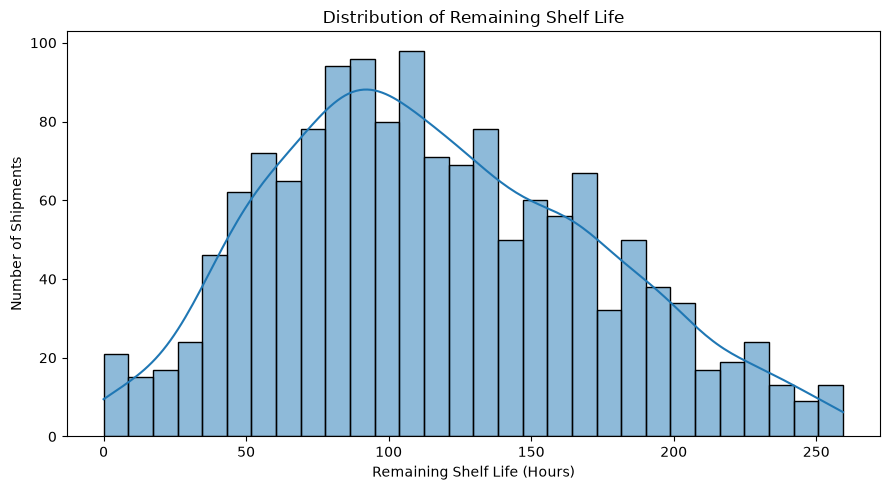

In [126]:
plt.figure(figsize=(9, 5))

sns.histplot(data=training_df,x="Remaining_Shelf_Life_Hours",bins=30,kde=True)

plt.title("Distribution of Remaining Shelf Life")
plt.xlabel("Remaining Shelf Life (Hours)")
plt.ylabel("Number of Shipments")
plt.tight_layout()
plt.show()

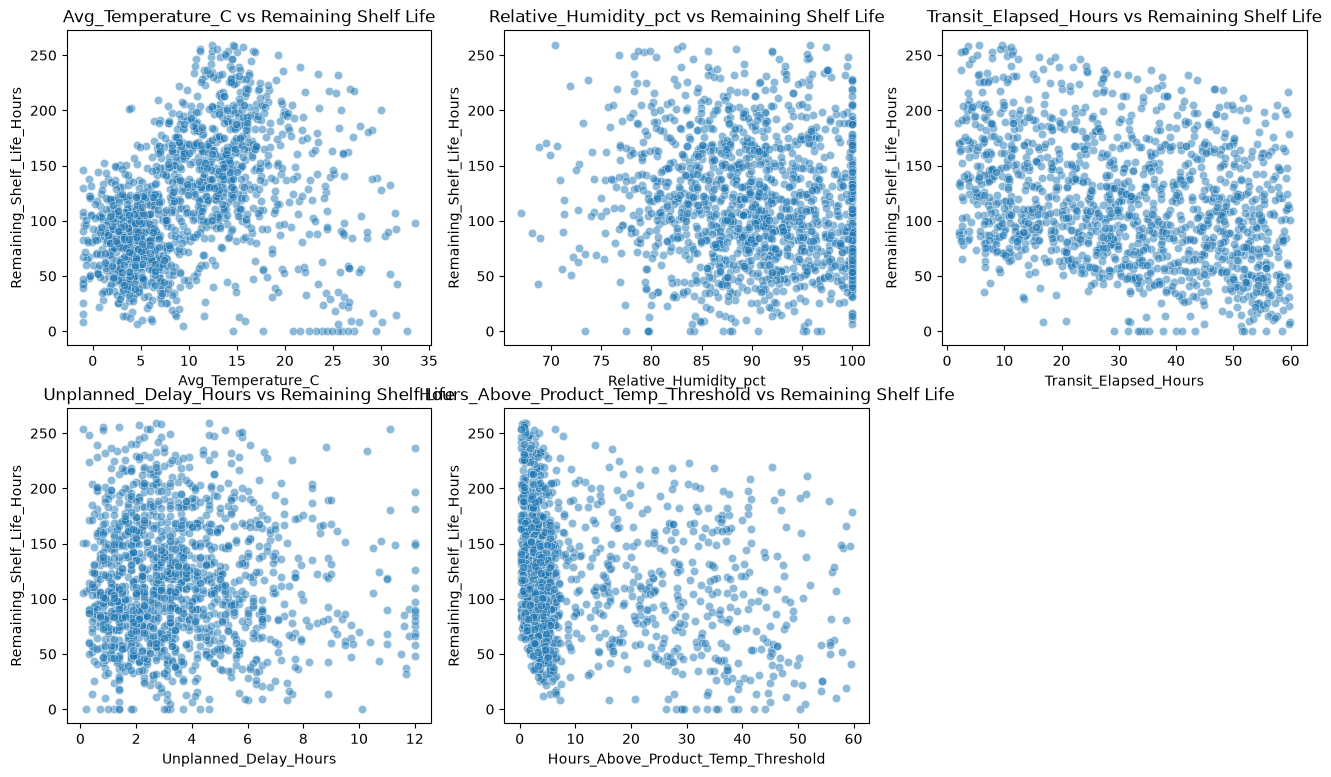

In [134]:
features_to_plot = ["Avg_Temperature_C","Relative_Humidity_pct","Transit_Elapsed_Hours","Unplanned_Delay_Hours","Hours_Above_Product_Temp_Threshold"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    sns.scatterplot(data=training_df,x=feature,y="Remaining_Shelf_Life_Hours",alpha=0.5,ax=axes[i])

    axes[i].set_title(f"{feature} vs Remaining Shelf Life")


fig.delaxes(axes[5]) # Removed the unused sixth plot

plt.show()

In [136]:
numerical_columns = [
    "Initial_Shelf_Life_Hours",
    "Avg_Temperature_C",
    "Temperature_Fluctuation_C",
    "Relative_Humidity_pct",
    "Transit_Elapsed_Hours",
    "Expected_Transit_Remaining_Hours",
    "Hours_Above_Product_Temp_Threshold",
    "Unplanned_Delay_Hours",
    "Remaining_Shelf_Life_Hours"
]

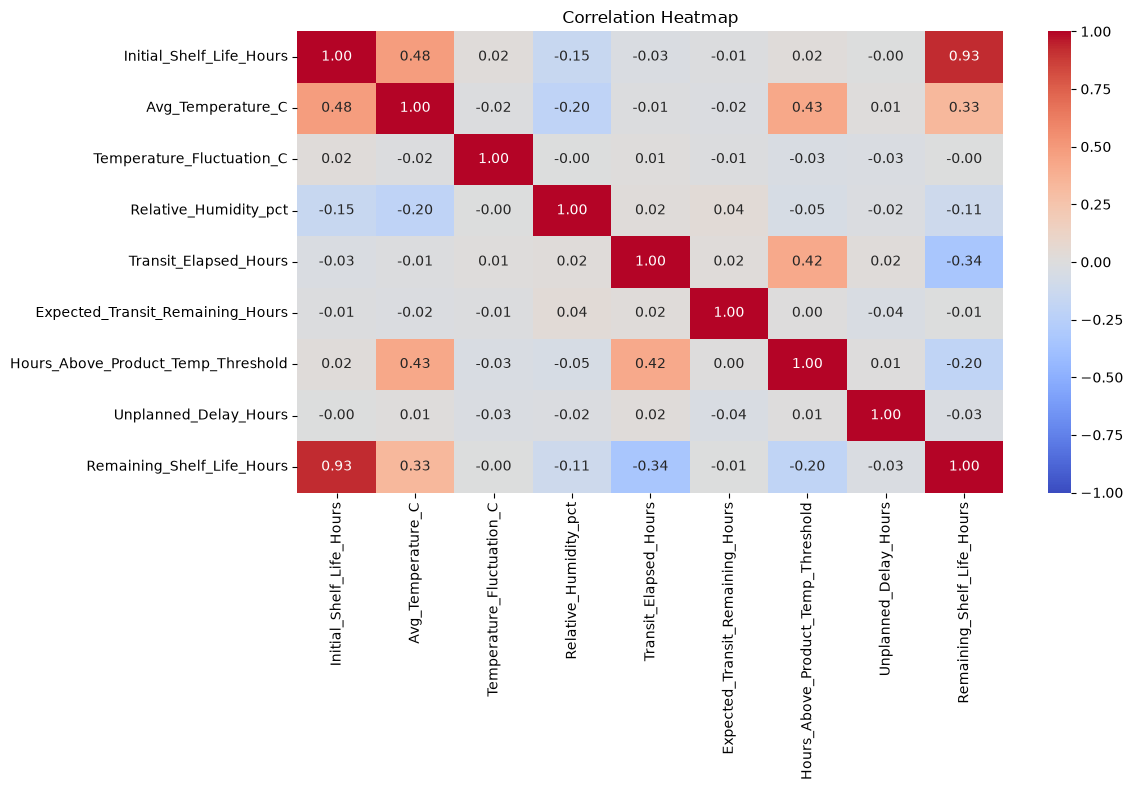

In [137]:
correlation_matrix = training_df[
    numerical_columns
].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

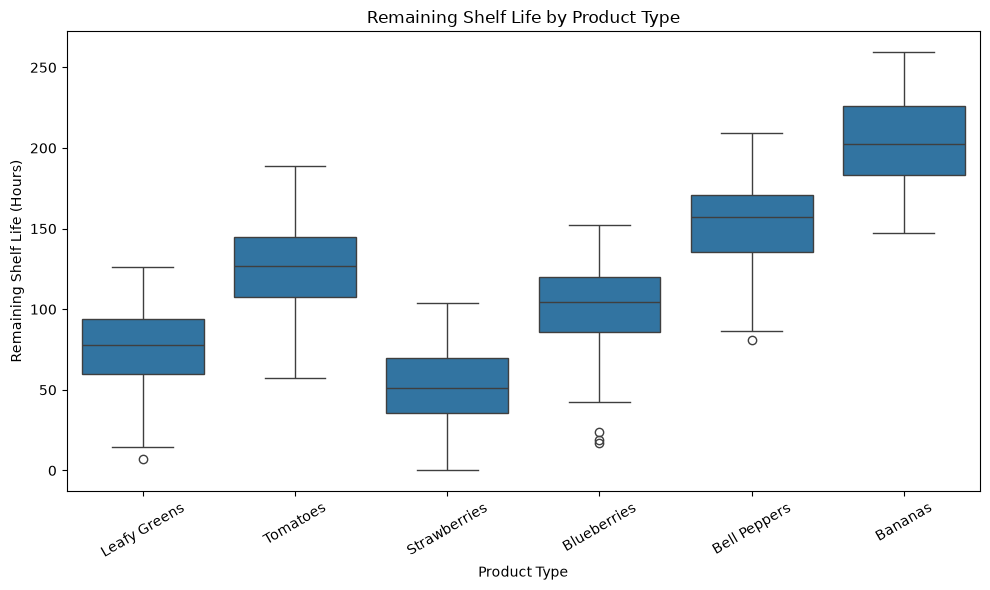

In [138]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=training_df,
    x="Product_Type",
    y="Remaining_Shelf_Life_Hours"
)

plt.title("Remaining Shelf Life by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Remaining Shelf Life (Hours)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


##### Since we have seen that the correlation of 0.93 between Initial Shelf Life Hours and Remaining Shelf Life Hours is very high. This means shipments starting with a longer shelf life tend to retain a longer shelf life in the dataset.

##### So now, before proceeding to anything else, it would be better to investigate the realtionship between initial Shelf Life Hours and remaining Shelf Life Hours.

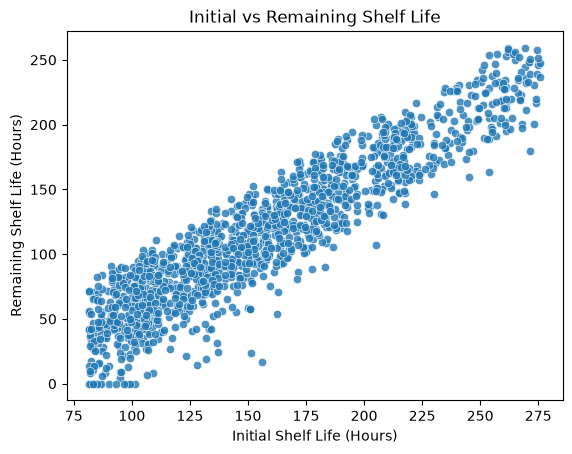

In [140]:
sns.scatterplot(
    data=training_df,
    x="Initial_Shelf_Life_Hours",
    y="Remaining_Shelf_Life_Hours",
    alpha=0.8)

plt.title("Initial vs Remaining Shelf Life")
plt.xlabel("Initial Shelf Life (Hours)")
plt.ylabel("Remaining Shelf Life (Hours)")
plt.show()